# Amazon Baby Reviews — Data Analysis

## Test 1 — Loading and inspecting the data

Loading the CSV file. Checking its size, columns, data types, and first few rows.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 5)

df = pd.read_csv("amazon_baby.csv")

print("Number of rows and columns:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)

df.head()

Number of rows and columns: (183531, 3)

Column names: ['name', 'review', 'rating']

Data types:
name        str
review      str
rating    int64
dtype: object


,name,review,rating
0,Planetwise Flannel Wipes,"These flannel wipes are OK, but in my opinion ...",3
1,Planetwise Wipe Pouch,it came early and was not disappointed. i love...,5
2,Annas Dream Full Quilt with 2 Shams,Very soft and comfortable and warmer than it l...,5
3,Stop Pacifier Sucking without tears with Thumb...,This is a product well worth the purchase. I ...,5
4,Stop Pacifier Sucking without tears with Thumb...,All of my kids have cried non-stop when I trie...,5


## Test 2 — Checking data quality

Finding missing values, exact duplicate rows, and the number of distinct products. Does not remove rows automatically but instead duplicated reviews may be real repeated records, so first inspect how many there are.

In [3]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})

print("Missing values by column:")
display(missing_summary)

print("Exact duplicate rows:", df.duplicated().sum())
print("Distinct product names:", df["name"].nunique(dropna=True))
print("Ratings outside the range 1–5:", (~df["rating"].between(1, 5)).sum())

Missing values by column:


,missing_count,missing_percent
name,318,0.17
review,829,0.45
rating,0,0.00


Exact duplicate rows: 62
Distinct product names: 32417
Ratings outside the range 1–5: 0


## Test 3 — Understanding the ratings

 Calculating the mean and median rating. Then Showing the count and percentage of reviews for each rating. And lastly ploting the rating counts.

Mean rating: 4.12
Median rating: 5.0


,number_of_reviews,percent
rating,,
1,15183,8.27
2,11310,6.16
3,16779,9.14
4,33205,18.09
5,107054,58.33


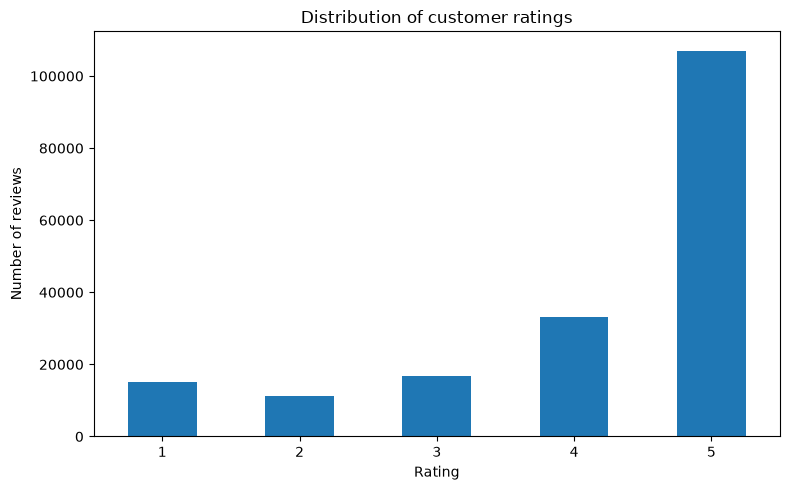

In [4]:
rating_summary = df["rating"].value_counts().sort_index().to_frame("number_of_reviews")
rating_summary["percent"] = (rating_summary["number_of_reviews"] / len(df) * 100).round(2)

print("Mean rating:", round(df["rating"].mean(), 2))
print("Median rating:", df["rating"].median())
display(rating_summary)

rating_summary["number_of_reviews"].plot(kind="bar", rot=0)
plt.xlabel("Rating")
plt.ylabel("Number of reviews")
plt.title("Distribution of customer ratings")
plt.tight_layout()
plt.show()

## Test 4 — Measuring review length

Creating a variable with the number of words in each review. Showing basic statistics and plot the distribution. The histogram excludes the longest 1% of reviews only to make the common range easier to see,

Review word-count statistics:


,review_word_count
count,182702.0
mean,81.9
std,86.6
min,1.0
25%,31.0
50%,55.0
75%,100.0
max,2714.0


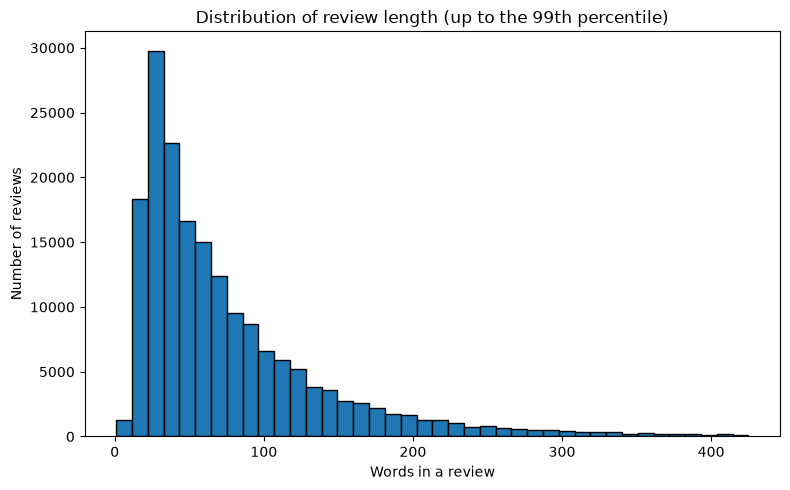

In [ ]:
df["review_word_count"] = df["review"].str.split().str.len()

print("Review word-count statistics:")
display(df["review_word_count"].describe().round(2).to_frame())

word_count_limit = df["review_word_count"].quantile(0.99)
words_for_plot = df.loc[
    df["review_word_count"].notna() & (df["review_word_count"] <= word_count_limit),
    "review_word_count"
]

plt.hist(words_for_plot, bins=40, edgecolor="black")
plt.xlabel("Words in a review")
plt.ylabel("Number of reviews")
plt.title("Distribution of review length (up to the 99th percentile)")
plt.tight_layout()
plt.show()

## Test 5 — Does review length differ by rating?

Comparing the mean and median number of words for each rating. Then using a boxplot to compare the distributions. The boxplot hides points above the 99th percentile and suppresses individual outlier markers.

,mean_words,median_words,reviews_with_text
rating,,,
1,88.71,65.0,15116
2,96.05,70.0,11277
3,93.71,65.0,16727
4,93.42,65.0,33099
5,74.00,49.0,106483


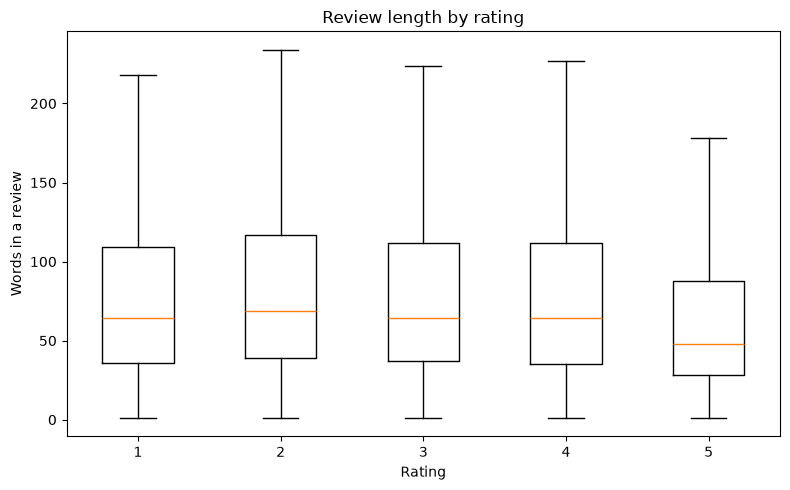

In [7]:
length_by_rating = df.groupby("rating")["review_word_count"].agg(
    mean_words="mean",
    median_words="median",
    reviews_with_text="count"
).round(2)

display(length_by_rating)

ratings = sorted(df["rating"].dropna().unique())
plot_df = df.loc[
    df["review_word_count"].notna() & (df["review_word_count"] <= word_count_limit)
]
box_data = [plot_df.loc[plot_df["rating"] == rating, "review_word_count"] for rating in ratings]

plt.boxplot(box_data, label=ratings, showfliers=False)
plt.xlabel("Rating")
plt.ylabel("Words in a review")
plt.title("Review length by rating")
plt.tight_layout()
plt.show()

## Test 6 — Which products receive the most reviews?

Group reviews by product name. Showing the 10 products with the most reviews, including their average rating, and plot the review counts.

,number_of_reviews,average_rating,median_rating,five_star_percent
name,,,,
Vulli Sophie the Giraffe Teether,785,4.29,5.0,68.15
"Simple Wishes Hands-Free Breastpump Bra, Pink, XS-L",562,4.69,5.0,81.85
Infant Optics DXR-5 2.4 GHz Digital Video Baby Monitor with Night Vision,561,3.84,5.0,51.34
Baby Einstein Take Along Tunes,547,4.71,5.0,83.55
"Cloud b Twilight Constellation Night Light, Turtle",520,4.54,5.0,73.65
"Fisher-Price Booster Seat, Blue/Green/Gray",489,4.72,5.0,79.55
Fisher-Price Rainforest Jumperoo,450,4.70,5.0,80.22
"Graco Nautilus 3-in-1 Car Seat, Matrix",419,4.27,5.0,57.28
Leachco Snoogle Total Body Pillow,388,4.41,5.0,64.18


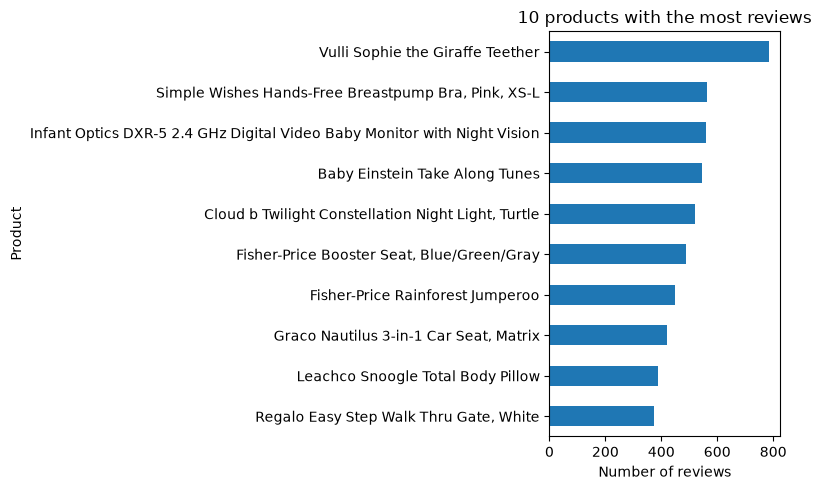

In [8]:
product_stats = df.dropna(subset=["name"]).groupby("name").agg(
    number_of_reviews=("rating", "count"),
    average_rating=("rating", "mean"),
    median_rating=("rating", "median"),
    five_star_percent=("rating", lambda ratings: ratings.eq(5).mean() * 100)
)

most_reviewed = product_stats.sort_values("number_of_reviews", ascending=False).head(10)
display(most_reviewed.round(2))

most_reviewed["number_of_reviews"].sort_values().plot(kind="barh")
plt.xlabel("Number of reviews")
plt.ylabel("Product")
plt.title("10 products with the most reviews")
plt.tight_layout()
plt.show()

## Test 7 — Comparing products with enough reviews

A product with only a few reviews can have an unusually high or low average by chance. Keeping only products with at least 100 reviews, then showing:

- the 10 highest average ratings;
- the 10 lowest average ratings.

The tables also show how many reviews each product has.

In [9]:
minimum_reviews = 100
popular_products = product_stats.loc[product_stats["number_of_reviews"] >= minimum_reviews]

print("Products with at least", minimum_reviews, "reviews:", len(popular_products))
print("\nHighest average ratings:")
display(
    popular_products.sort_values(["average_rating", "number_of_reviews"], ascending=[False, False])
    [["number_of_reviews", "average_rating", "median_rating", "five_star_percent"]]
    .head(10).round(2)
)

print("\nLowest average ratings:")
display(
    popular_products.sort_values(["average_rating", "number_of_reviews"], ascending=[True, False])
    [["number_of_reviews", "average_rating", "median_rating", "five_star_percent"]]
    .head(10).round(2)
)

Products with at least 100 reviews: 164

Highest average ratings:


,number_of_reviews,average_rating,median_rating,five_star_percent
name,,,,
"Itzy Ritzy Snack Happens Reusable Snack Bag, Rodeo Drive",106,4.81,5.0,87.74
"Aden By aden + anais Muslin Swaddle Blanket 4 Pack, Oh My!",133,4.79,5.0,85.71
"HALO SleepSack Micro-Fleece Wearable Blanket, Soft Pink, Small",124,4.78,5.0,87.90
"Angel Dear Blankie, Green Frog",123,4.77,5.0,86.99
"Fisher-Price Kick and Play Piano Gym, Discover 'N Grow",184,4.77,5.0,83.15
BABYBJORN Toilet Trainer - White/Red,139,4.74,5.0,80.58
"Baby Banana Bendable Training Toothbrush, Infant",158,4.72,5.0,83.54
"Carters Easy Fit Velour Plush Crib Fitted Sheet, Chocolate",122,4.72,5.0,82.79
Dr. Brown's Formula Mixing Pitcher,149,4.72,5.0,80.54



Lowest average ratings:


,number_of_reviews,average_rating,median_rating,five_star_percent
name,,,,
Safety 1st Deluxe 4-in-1 Bath Station,154,2.45,2.0,16.23
Potty Time Potty Watch - Blue,108,3.01,3.0,24.07
Philips Avent 3 Pack 9oz Bottles,191,3.20,4.0,34.55
"Dreambaby Stroller Fan, White/Blue",107,3.39,4.0,29.91
VTech Communications Safe &amp; Sound Digital Audio Monitor with two Parent Units,139,3.50,4.0,40.29
Zo-li Bot Straw Sippy Cup 6oz,152,3.55,4.0,36.18
DEX Products Sound Sleeper SS-01,103,3.55,4.0,43.69
NTM-910YIC - Sony Baby Call Nursery Monitor,284,3.57,4.0,47.54
Munchkin 3 Count Stay Put Suction Bowl,127,3.58,4.0,33.86


## Test 8 — Is popularity related to average rating?

Each point represents one product. Highlighting products with at least 100 reviews. The x-axis is logarithmic because products have very different review counts.

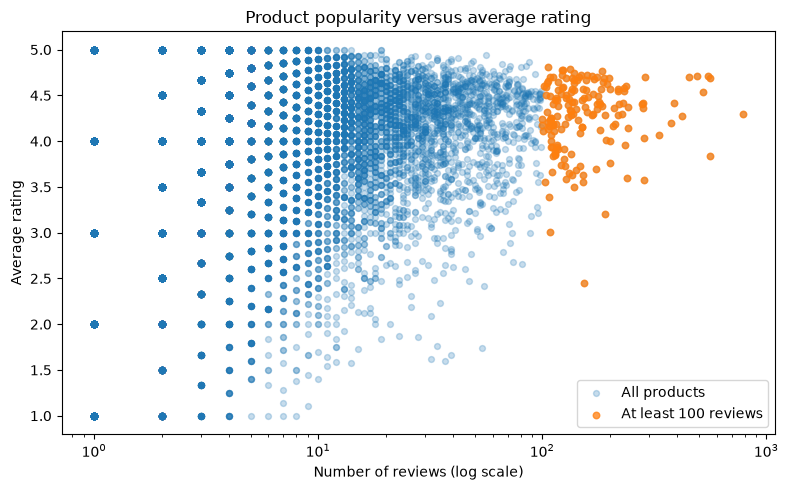

In [10]:
plt.scatter(
    product_stats["number_of_reviews"],
    product_stats["average_rating"],
    alpha=0.25,
    s=18,
    label="All products"
)
plt.scatter(
    popular_products["number_of_reviews"],
    popular_products["average_rating"],
    alpha=0.75,
    s=22,
    label="At least 100 reviews"
)
plt.xscale("log")
plt.xlabel("Number of reviews (log scale)")
plt.ylabel("Average rating")
plt.title("Product popularity versus average rating")
plt.legend()
plt.tight_layout()
plt.show()

## Test 9 — Comparing ratings for short and long reviews

Creating three groups based on review word count, then compare the **percentage** of each rating in every group. 

rating,1,2,3,4,5
review_length_group,,,,,
Short (0–25 words),6.0,3.8,6.2,14.2,69.7
Medium (26–75 words),8.0,5.7,9.0,17.0,60.3
Long (76+ words),9.6,7.8,10.7,21.4,50.5


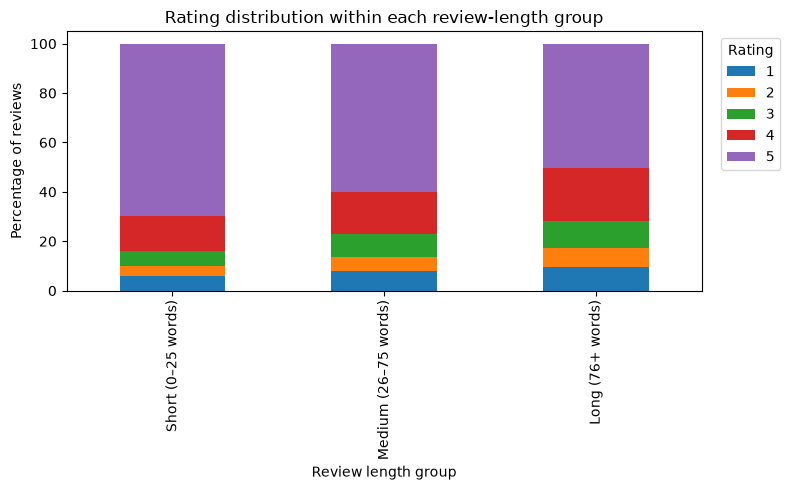

In [11]:
df["review_length_group"] = pd.cut(
    df["review_word_count"],
    bins=[-1, 25, 75, np.inf],
    labels=["Short (0–25 words)", "Medium (26–75 words)", "Long (76+ words)"]
)

rating_percentages = pd.crosstab(
    df["review_length_group"],
    df["rating"],
    normalize="index"
) * 100

display(rating_percentages.round(1))
rating_percentages.plot(kind="bar", stacked=True)
plt.xlabel("Review length group")
plt.ylabel("Percentage of reviews")
plt.title("Rating distribution within each review-length group")
plt.legend(title="Rating", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()